# **Imports & reproducibility**

In [29]:
import os
import random
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Python environment ready")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python environment ready
pandas: 2.2.3
NumPy: 2.1.3


# **Connect Google Drive & set paths**

In [30]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/Image_tagging")
CSV_DIR = DRIVE_DIR
RAR_PATH = DRIVE_DIR / "NUS_WIDE.rar"
DATA_DIR = Path("/content/datasets/NUS_WIDE")
PREFIX = "nuswide_top30_60k5k10k_stratified_"
SPLITS = {"train": 60000, "validation": 5000, "test": 10000}
CSV_PATHS = {s: CSV_DIR / f"{PREFIX}{s}.csv" for s in SPLITS}

assert DRIVE_DIR.is_dir(), f"Google Drive folder not found: {DRIVE_DIR}"
for split, path in CSV_PATHS.items():
    assert path.is_file(), f"Missing CSV ({split}): {path}"
print("CSV files found:")
for split, path in CSV_PATHS.items():
    print(split, "->", path.name)
print("RAR exists:", RAR_PATH.is_file())
print("Image directory exists:", DATA_DIR.is_dir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV files found:
train -> nuswide_top30_60k5k10k_stratified_train.csv
validation -> nuswide_top30_60k5k10k_stratified_validation.csv
test -> nuswide_top30_60k5k10k_stratified_test.csv
RAR exists: True
Image directory exists: True


# **Prepare image folders (idempotent)**

In [31]:
!command -v unrar || (apt-get update -qq && apt-get install -y unrar)
!unrar | head -n 2

/usr/bin/unrar

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


In [32]:
# ==========================================
# PREPARE IMAGE FOLDERS (IDEMPOTENT)
# ==========================================

from pathlib import Path
from PIL import Image
import subprocess
import shutil

DATA_ROOT = Path("/content/datasets/NUS_WIDE")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

EXPECTED_COUNTS = {
    "train": 60000,
    "validation": 5000,
    "test": 10000
}

def count_images():
    return {
        split: sum(
            1 for p in (DATA_ROOT / split).rglob("*")
            if p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png"}
        )
        for split in EXPECTED_COUNTS
    }

counts = count_images()
print("Image counts before extraction:", counts)

# Extract only when image counts are incomplete
if counts != EXPECTED_COUNTS:

    print("Dataset incomplete. Extracting with unrar...")

    if shutil.which("unrar") is None:
        raise RuntimeError(
            "unrar is not installed. Install it before extraction."
        )

    result = subprocess.run(
        [
            "unrar", "x", "-o+",
            str(RAR_PATH),
            str(DATA_ROOT) + "/"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Extraction failed:\n" +
            (result.stdout + result.stderr)[-2000:]
        )

    print("Extraction completed successfully.")

else:
    print("All image files already exist. Skipping extraction.")

# Final count check
counts = count_images()

print("\n===== FINAL IMAGE COUNTS =====")
for split, count in counts.items():
    print(f"{split}: {count:,} images")

assert counts == EXPECTED_COUNTS, (
    "Image counts do not match expected dataset sizes!"
)

print("\nSUCCESS: All 75,000 image files found!")

Image counts before extraction: {'train': 60000, 'validation': 5000, 'test': 10000}
All image files already exist. Skipping extraction.

===== FINAL IMAGE COUNTS =====
train: 60,000 images
validation: 5,000 images
test: 10,000 images

SUCCESS: All 75,000 image files found!


In [33]:

# ==========================================
# VERIFY ALL EXTRACTED IMAGES
# ==========================================

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

DATA_ROOT = Path("/content/datasets/NUS_WIDE")

expected_counts = {
    "train": 60000,
    "validation": 5000,
    "test": 10000
}

corrupted_images = []

for split, expected in expected_counts.items():

    folder = DATA_ROOT / split
    image_paths = sorted(folder.rglob("*.jpg"))

    print(f"\n===== {split.upper()} =====")
    print("Found:", len(image_paths))
    print("Expected:", expected)

    assert len(image_paths) == expected, (
        f"Incorrect image count in {split}"
    )

    for path in tqdm(image_paths, desc=f"Checking {split}"):

        try:
            with Image.open(path) as img:
                img.verify()

            # Verify that pixel data can actually be decoded
            with Image.open(path) as img:
                img.load()

        except Exception as e:
            corrupted_images.append((str(path), str(e)))

print("\n===== FINAL INTEGRITY RESULT =====")
print("Total images checked:", sum(expected_counts.values()))
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nFirst 20 corrupted files:")
    for path, error in corrupted_images[:20]:
        print(path, "->", error)
else:
    print("SUCCESS: All 75,000 images passed verification!")



===== TRAIN =====
Found: 60000
Expected: 60000


Checking train:   0%|          | 0/60000 [00:00<?, ?it/s]


===== VALIDATION =====
Found: 5000
Expected: 5000


Checking validation:   0%|          | 0/5000 [00:00<?, ?it/s]


===== TEST =====
Found: 10000
Expected: 10000


Checking test:   0%|          | 0/10000 [00:00<?, ?it/s]


===== FINAL INTEGRITY RESULT =====
Total images checked: 75000
Corrupted images: 0
SUCCESS: All 75,000 images passed verification!


# **Load original CSV splits & define exact label order**

In [34]:
train_df = pd.read_csv(CSV_PATHS["train"])
val_df = pd.read_csv(CSV_PATHS["validation"])
test_df = pd.read_csv(CSV_PATHS["test"])

LABEL_COLUMNS = [
    "sky", "clouds", "person", "water", "animal", "grass", "buildings",
    "window", "plants", "lake", "ocean", "road", "flowers", "sunset",
    "reflection", "rocks", "vehicle", "snow", "tree", "beach", "mountain",
    "boats", "nighttime", "house", "valley", "birds", "sun", "military",
    "garden", "toy"
]

datasets = {"train": train_df, "validation": val_df, "test": test_df}
for split, df in datasets.items():
    assert list(df.columns[1:31]) == LABEL_COLUMNS, f"Incorrect label order in {split}"
    print(f"{split}: {df.shape}")
print("Labels:", LABEL_COLUMNS)
display(train_df.head(3))

train: (60000, 33)
validation: (5000, 33)
test: (10000, 33)
Labels: ['sky', 'clouds', 'person', 'water', 'animal', 'grass', 'buildings', 'window', 'plants', 'lake', 'ocean', 'road', 'flowers', 'sunset', 'reflection', 'rocks', 'vehicle', 'snow', 'tree', 'beach', 'mountain', 'boats', 'nighttime', 'house', 'valley', 'birds', 'sun', 'military', 'garden', 'toy']


,image,sky,clouds,person,water,animal,grass,buildings,window,plants,...,nighttime,house,valley,birds,sun,military,garden,toy,_matched_top30_count,_matched_top30_labels
0,canoe\0435_2614631664.jpg,0,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,clouds|person|water|lake
1,throwing\0523_516408436.jpg,0,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,clouds|person|water|lake
2,costume\0343_131800162.jpg,0,1,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,clouds|person|water|lake


# **Resolve flat-directory image paths**

In [35]:
def resolve_image_path(image_name, split):
    if split not in SPLITS:
        raise ValueError(f"Unknown split: {split}")
    normalized = str(image_name).replace("\\", "/")
    filename = Path(normalized).name
    return DATA_DIR / split / filename

sample_name = train_df.iloc[0]["image"]
sample_path = resolve_image_path(sample_name, "train")
print("CSV filename:", sample_name)
print("Resolved path:", sample_path)
print("Exists:", sample_path.is_file())
assert sample_path.is_file(), "Sample image missing"

CSV filename: canoe\0435_2614631664.jpg
Resolved path: /content/datasets/NUS_WIDE/train/0435_2614631664.jpg
Exists: True


# **Data integrity check**

In [36]:
for split, df in datasets.items():
    missing = int(df[["image"] + LABEL_COLUMNS].isna().sum().sum())
    invalid = int((~df[LABEL_COLUMNS].isin([0, 1])).sum().sum())
    dup = int(df["image"].duplicated().sum())
    avg = float(df[LABEL_COLUMNS].sum(axis=1).mean())
    zero = int((df[LABEL_COLUMNS].sum(axis=1) == 0).sum())
    print(f"\n===== {split.upper()} =====")
    print("Shape:", df.shape, "Missing:", missing,
          "Invalid labels:", invalid, "Duplicates:", dup)
    print("Avg labels/image:", round(avg, 3), "Zero-label images:", zero)
    assert len(df) == SPLITS[split], "Unexpected split size"
    assert df.shape[1] == 33, "Unexpected number of CSV columns"
    assert missing == invalid == dup == 0, "Data integrity failed"

images_by_split = {s: set(df["image"].astype(str).str.replace("\\", "/", regex=False)
                                 .str.rsplit("/", n=1).str[-1])
                   for s, df in datasets.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = len(images_by_split[a] & images_by_split[b])
    print(f"{a} vs {b} filename overlap:", overlap)
    assert overlap == 0, "Split leakage detected"
print("\nSUCCESS: DATA INTEGRITY CHECK PASSED")


===== TRAIN =====
Shape: (60000, 33) Missing: 0 Invalid labels: 0 Duplicates: 0
Avg labels/image: 2.211 Zero-label images: 0

===== VALIDATION =====
Shape: (5000, 33) Missing: 0 Invalid labels: 0 Duplicates: 0
Avg labels/image: 2.266 Zero-label images: 0

===== TEST =====
Shape: (10000, 33) Missing: 0 Invalid labels: 0 Duplicates: 0
Avg labels/image: 2.183 Zero-label images: 0
train vs validation filename overlap: 0
train vs test filename overlap: 0
validation vs test filename overlap: 0

SUCCESS: DATA INTEGRITY CHECK PASSED


# **Verify every CSV image path**

In [37]:
for split, df in datasets.items():
    missing_names = [name for name in df["image"]
                     if not resolve_image_path(name, split).is_file()]
    matched = len(df) - len(missing_names)
    print(f"{split}: {matched:,}/{len(df):,} matched; missing={len(missing_names)}")
    assert not missing_names, f"Missing example(s): {missing_names[:5]}"
print("SUCCESS: All 75,000 CSV image paths matched")

train: 60,000/60,000 matched; missing=0
validation: 5,000/5,000 matched; missing=0
test: 10,000/10,000 matched; missing=0
SUCCESS: All 75,000 CSV image paths matched


# **Visualize sample images and ground-truth tags**

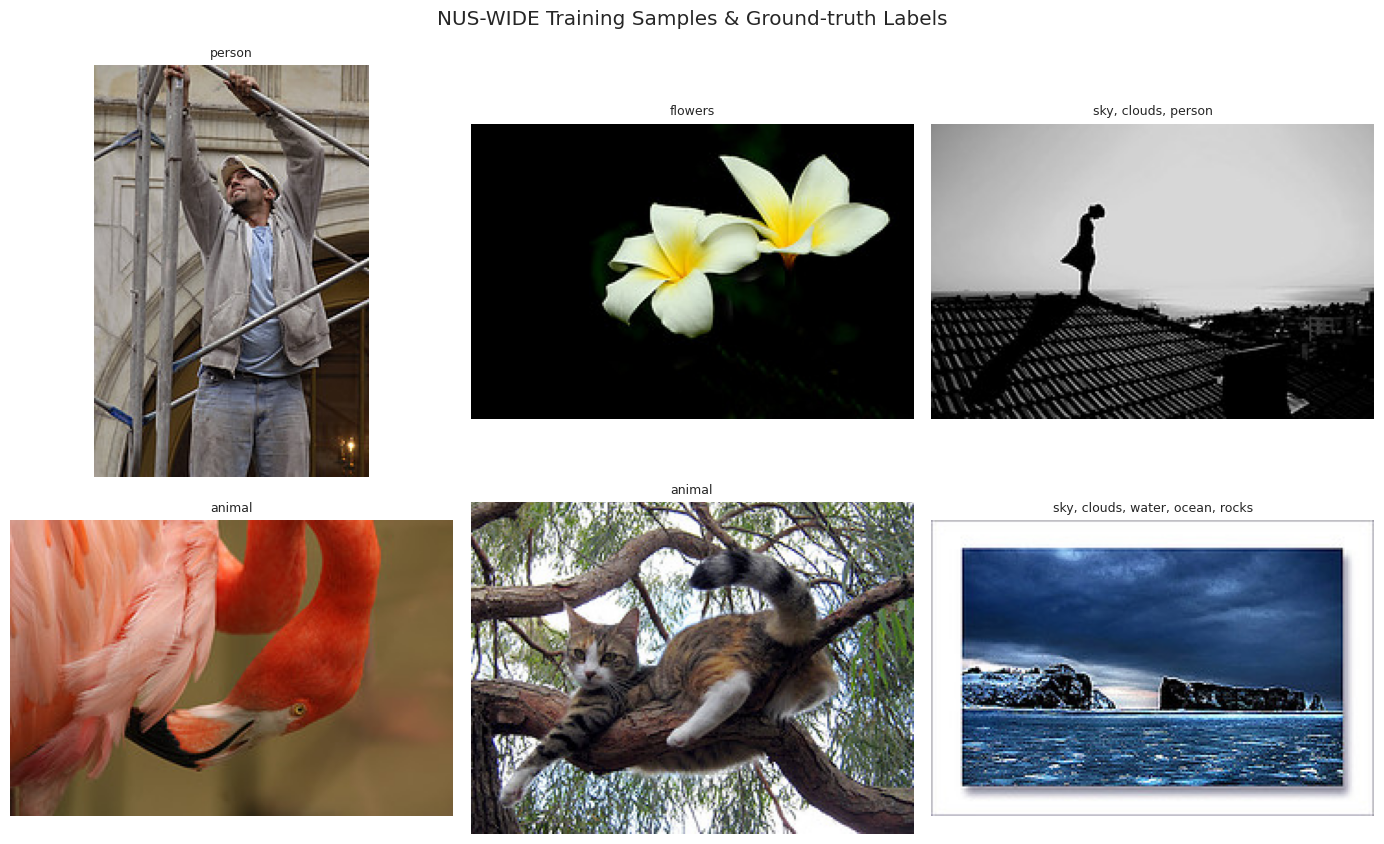

In [38]:
sample_rows = train_df.sample(n=6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    path = resolve_image_path(row["image"], "train")
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    labels = [c for c in LABEL_COLUMNS if row[c] == 1]
    ax.set_title(", ".join(labels), fontsize=9, wrap=True)
    ax.axis("off")
plt.suptitle("NUS-WIDE Training Samples & Ground-truth Labels")
plt.tight_layout()
plt.show()

# **EDA — Label distribution**

,Count,Percentage (%)
sky,22302,37.17
clouds,16239,27.06
person,15494,25.82
water,10569,17.61
animal,10186,16.98
grass,6755,11.26
buildings,5328,8.88
window,4519,7.53
plants,4281,7.14
lake,3977,6.63


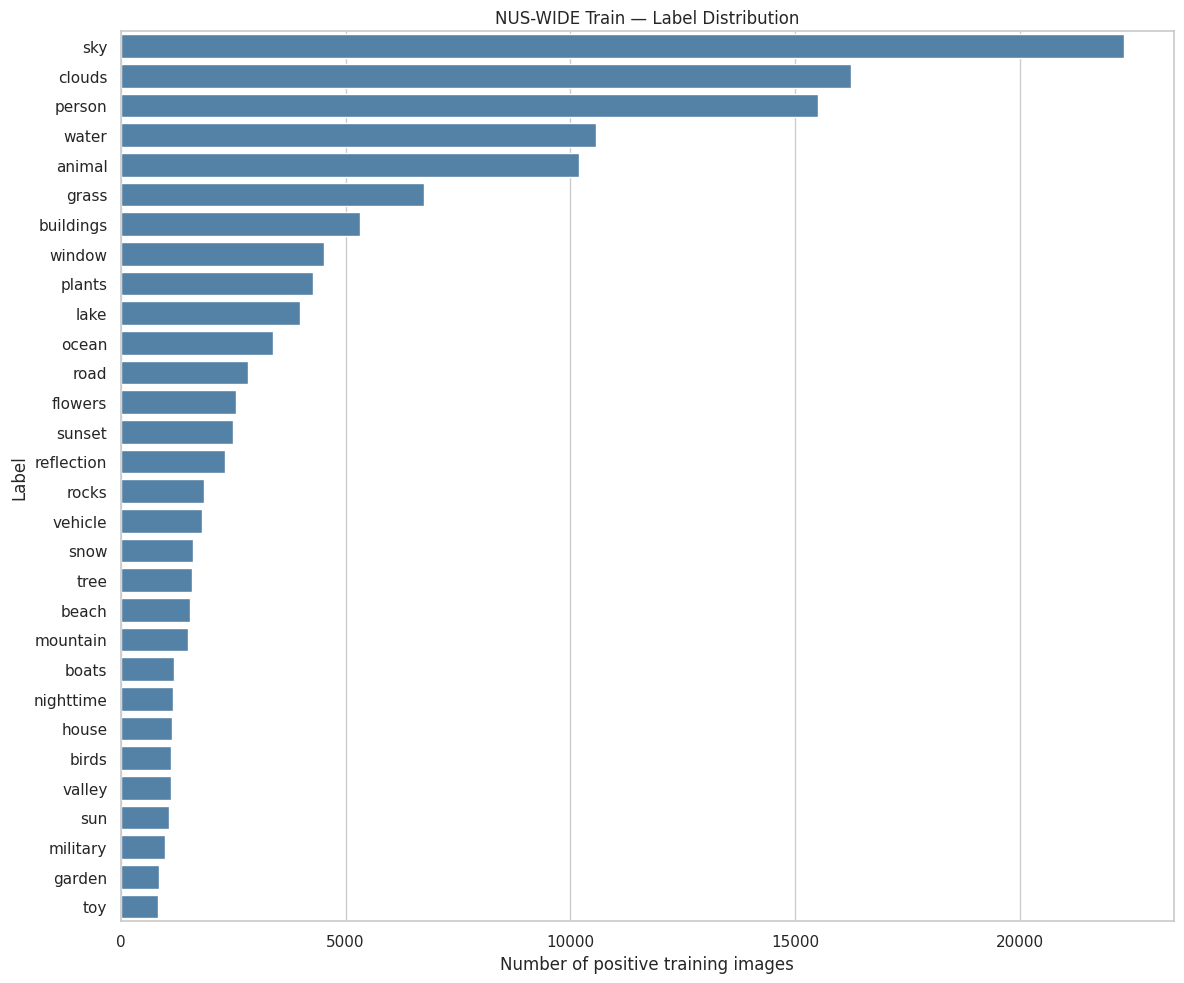

In [39]:
label_counts = train_df[LABEL_COLUMNS].sum().sort_values(ascending=False)
label_pct = label_counts / len(train_df) * 100
label_summary = pd.DataFrame({"Count": label_counts.astype(int),
                              "Percentage (%)": label_pct.round(2)})
display(label_summary)
plt.figure(figsize=(12, 10))
sns.barplot(x=label_counts.values, y=label_counts.index, color="steelblue")
plt.xlabel("Number of positive training images")
plt.ylabel("Label")
plt.title("NUS-WIDE Train — Label Distribution")
plt.tight_layout()
plt.show()

# **EDA — Class imbalance**

Most frequent: sky 22302
Least frequent: toy 834
Imbalance ratio: 26.74x


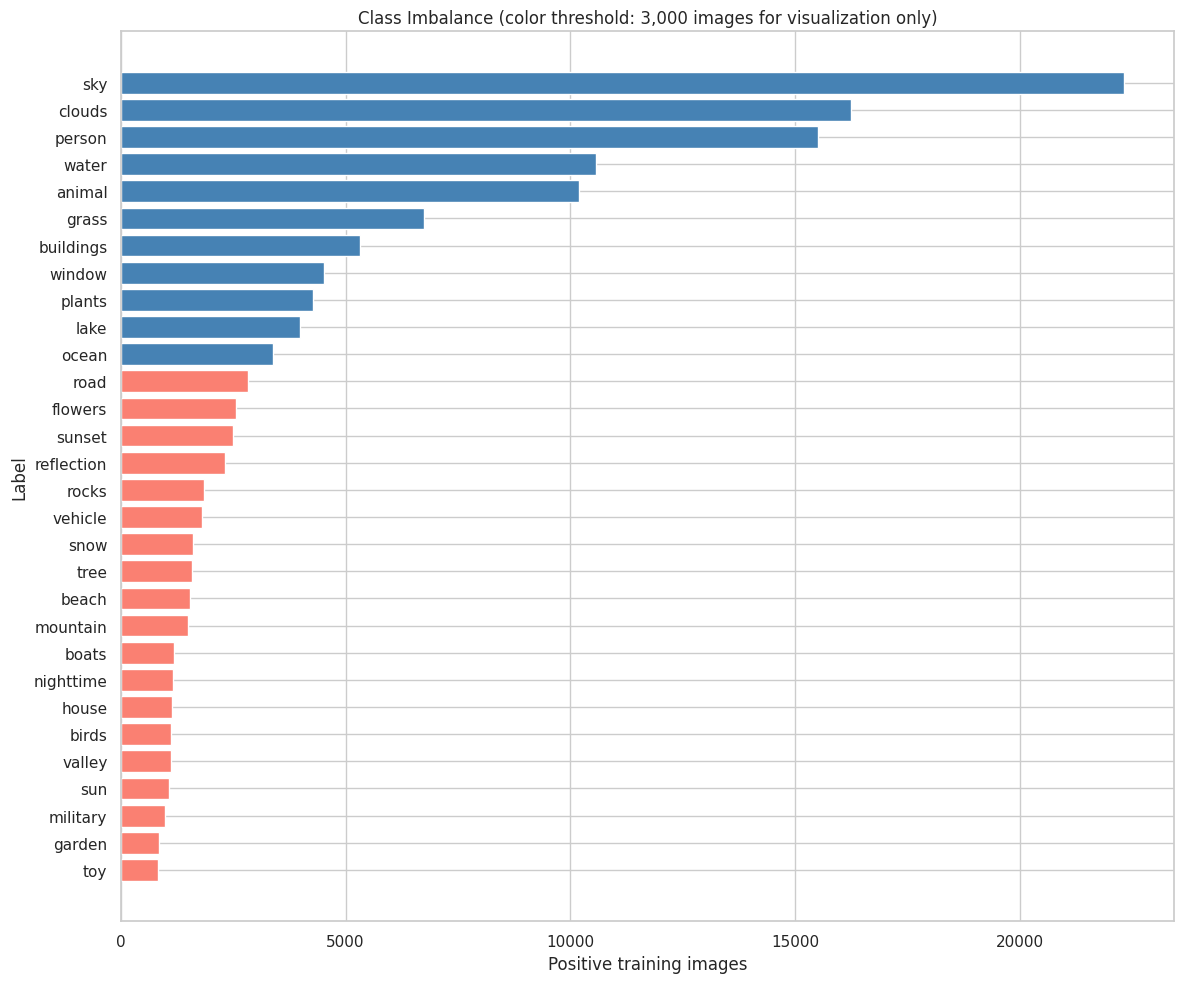

In [40]:
assert int(label_counts.min()) > 0, "At least one label has zero positives"
imbalance_ratio = label_counts.max() / label_counts.min()
print("Most frequent:", label_counts.idxmax(), int(label_counts.max()))
print("Least frequent:", label_counts.idxmin(), int(label_counts.min()))
print(f"Imbalance ratio: {imbalance_ratio:.2f}x")
fig, ax = plt.subplots(figsize=(12, 10))
colors = ["steelblue" if x >= 3000 else "salmon" for x in label_counts]
ax.barh(label_counts.index, label_counts.values, color=colors)
ax.invert_yaxis()
ax.set(xlabel="Positive training images", ylabel="Label",
       title="Class Imbalance (color threshold: 3,000 images for visualization only)")
plt.tight_layout()
plt.show()

# **EDA — Labels per image**

Summary:


,mean,median,min,max
train,2.211,2.0,1.0,11.0
validation,2.266,2.0,1.0,10.0
test,2.183,2.0,1.0,10.0


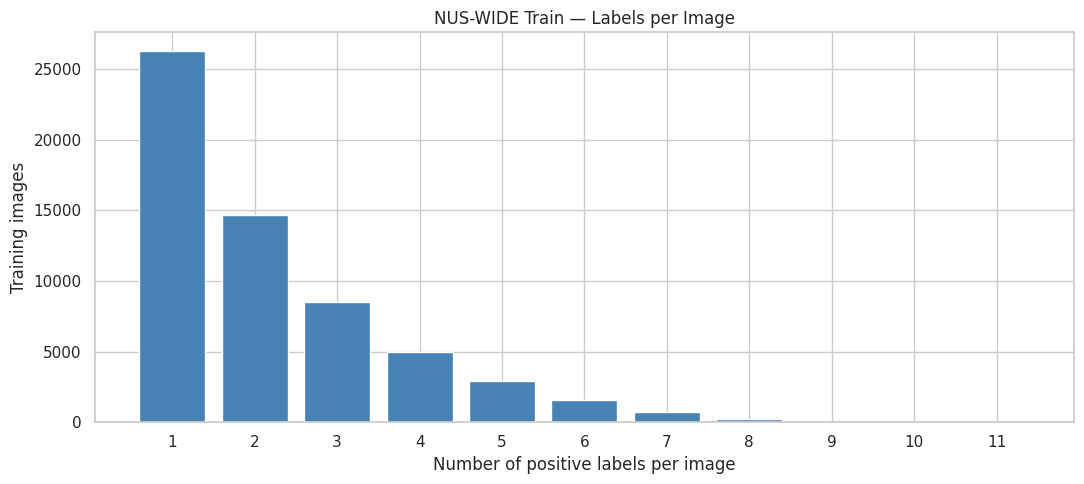

In [41]:
label_count_series = {split: df[LABEL_COLUMNS].sum(axis=1).astype(int)
                      for split, df in datasets.items()}
summary = pd.DataFrame({s: {"mean": x.mean(), "median": x.median(),
                            "min": x.min(), "max": x.max()}
                        for s, x in label_count_series.items()}).T
print("Summary:")
display(summary.round(3))
fig, ax = plt.subplots(figsize=(11, 5))
counts = label_count_series["train"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="steelblue")
ax.set(xlabel="Number of positive labels per image", ylabel="Training images",
       title="NUS-WIDE Train — Labels per Image")
ax.set_xticks(counts.index)
plt.tight_layout()
plt.show()

# **EDA — Label co-occurrence**

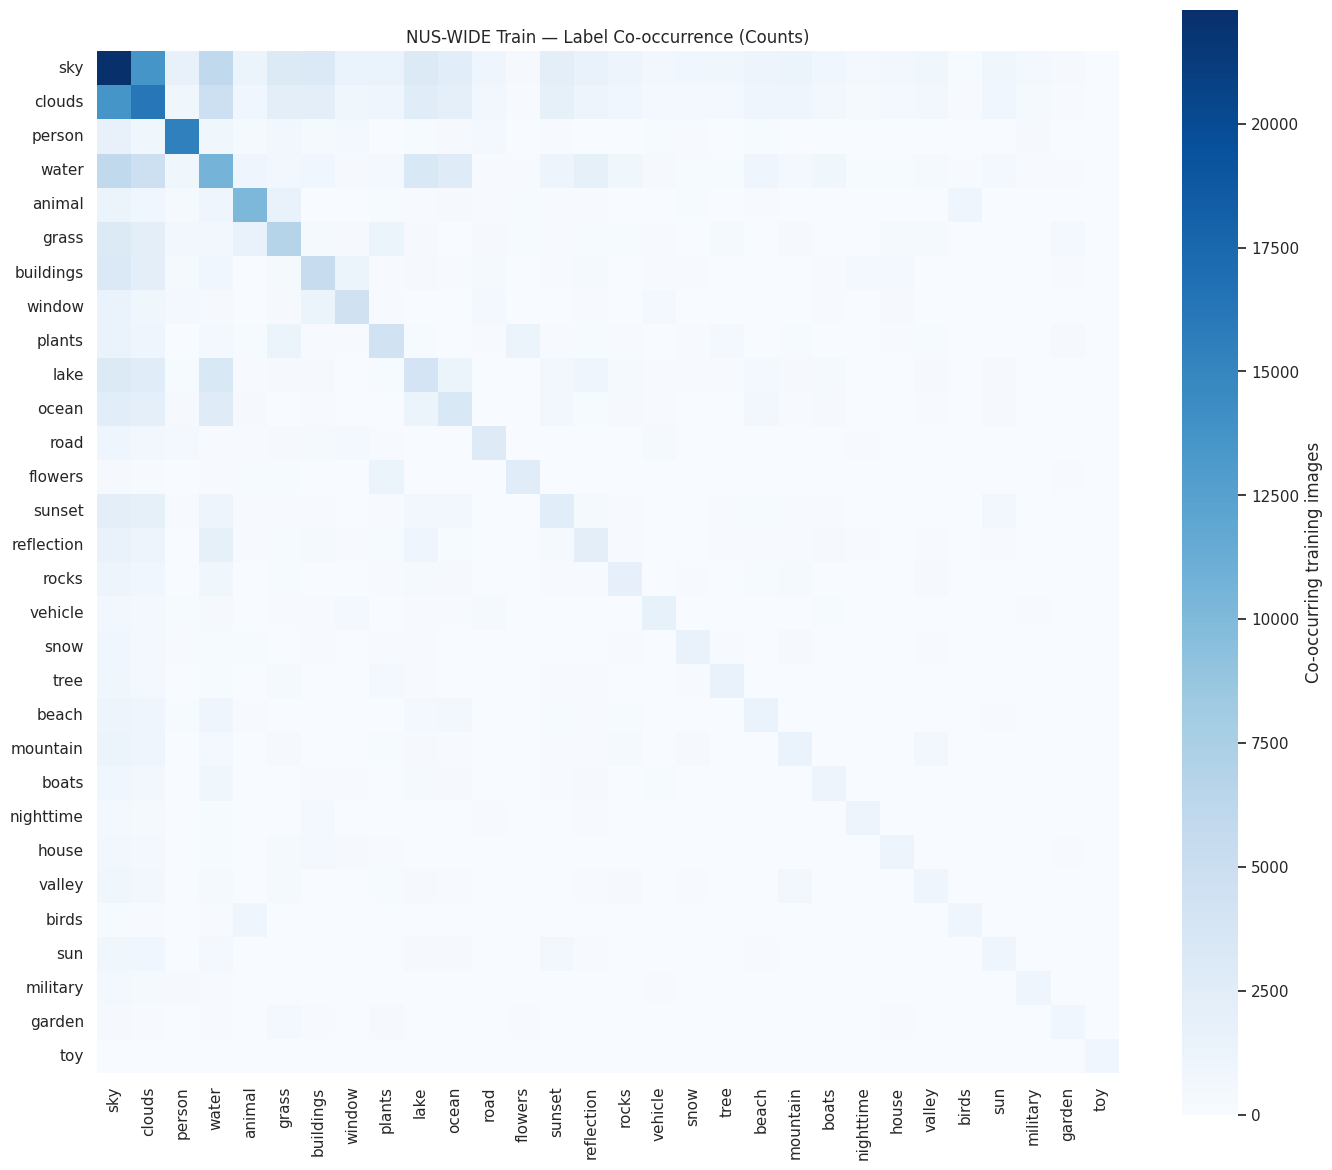

Top 10 co-occurring label pairs:


,Label A,Label B,Co-occurrence
0,sky,clouds,13637
1,sky,water,5949
2,clouds,water,4712
3,water,lake,3373
4,sky,buildings,3174
5,sky,lake,3043
6,sky,grass,2979
7,water,ocean,2769
8,clouds,lake,2528
9,sky,ocean,2452


In [42]:
Y_train = train_df[LABEL_COLUMNS].to_numpy(dtype=np.int64)
cooccurrence = Y_train.T @ Y_train
cooccurrence_df = pd.DataFrame(cooccurrence, index=LABEL_COLUMNS, columns=LABEL_COLUMNS)
plt.figure(figsize=(14, 12))
sns.heatmap(cooccurrence_df, cmap="Blues", square=True,
            cbar_kws={"label": "Co-occurring training images"})
plt.title("NUS-WIDE Train — Label Co-occurrence (Counts)")
plt.tight_layout()
plt.show()

pairs = []
for i in range(len(LABEL_COLUMNS)):
    for j in range(i + 1, len(LABEL_COLUMNS)):
        pairs.append((LABEL_COLUMNS[i], LABEL_COLUMNS[j], int(cooccurrence[i, j])))
top_pairs = pd.DataFrame(pairs, columns=["Label A", "Label B", "Co-occurrence"])
print("Top 10 co-occurring label pairs:")
display(top_pairs.sort_values("Co-occurrence", ascending=False).head(10).reset_index(drop=True))

# **Feature Extraction**

## Step 1: Environment and Dataset Readiness Check

In [43]:
# ==================================================
# PHASE 2 - STEP 1: ENVIRONMENT READINESS CHECK
# ==================================================

import os
import torch
import numpy as np
import pandas as pd
import sklearn
import torchvision

from pathlib import Path

print("===== SYSTEM INFORMATION =====")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\n===== GPU INFORMATION =====")

if torch.cuda.is_available():
    print("GPU available: YES")
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("GPU available: NO")
    print("Using CPU")

print("\n===== DATASET INFORMATION =====")

datasets = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in datasets.items():
    print(f"{name}: {len(df):,} images")

print("\nNumber of labels:", len(LABEL_COLUMNS))

print("\n===== IMAGE PATH CHECK =====")

for split in ["train", "validation", "test"]:

    folder = Path("/content/datasets/NUS_WIDE") / split

    print(
        f"{split}:",
        "FOUND" if folder.exists() else "NOT FOUND"
    )

print("\n===== STORAGE INFORMATION =====")

import shutil

disk = shutil.disk_usage("/content")

print("Free disk space (GB):",
      round(disk.free / 1024**3, 2))

print("\n===== READY FOR FEATURE EXTRACTION =====")

===== SYSTEM INFORMATION =====
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Scikit-learn version: 1.6.1

===== GPU INFORMATION =====
GPU available: YES
GPU name: Tesla T4
GPU memory (GB): 14.56

===== DATASET INFORMATION =====
Train: 60,000 images
Validation: 5,000 images
Test: 10,000 images

Number of labels: 30

===== IMAGE PATH CHECK =====
train: FOUND
validation: FOUND
test: FOUND

===== STORAGE INFORMATION =====
Free disk space (GB): 66.85

===== READY FOR FEATURE EXTRACTION =====
